<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Generative adversarial networks</b></h3>



В этом домашнем задании вы обучите GAN генерировать лица людей и посмотрите на то, как можно оценивать качество генерации

In [1]:
import os
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision.datasets import ImageFolder
import torchvision.transforms as tt
import torch
import torch.nn as nn
import cv2
from tqdm.notebook import tqdm
from torchvision.utils import save_image
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sns.set(style='darkgrid', font_scale=1.2)

## Часть 1. Подготовка данных (1 балл)

В качестве обучающей выборки возьмем часть датасета [Flickr Faces](https://github.com/NVlabs/ffhq-dataset), который содержит изображения лиц людей в высоком разрешении (1024х1024). Оригинальный датасет очень большой, поэтому мы возьмем его часть. Скачать датасет можно [здесь](https://www.kaggle.com/datasets/tommykamaz/faces-dataset-small?resource=download-directory) и  [здесь](https://drive.google.com/file/d/1inyvLrN5wKBGCxQ4znMKBc64uL4uP_2x/view?usp=drive_link)

Давайте загрузим наши изображения. Напишите функцию, которая строит DataLoader для изображений, при этом меняя их размер до нужного значения (размер 1024 слишком большой, поэтому мы рекомендуем взять размер 128 либо немного больше)

In [2]:
!gdown 1inyvLrN5wKBGCxQ4znMKBc64uL4uP_2x

Downloading...
From (original): https://drive.google.com/uc?id=1inyvLrN5wKBGCxQ4znMKBc64uL4uP_2x
From (redirected): https://drive.google.com/uc?id=1inyvLrN5wKBGCxQ4znMKBc64uL4uP_2x&confirm=t&uuid=6c371fc9-d429-4d54-a1d7-7d354be1598e
To: /kaggle/working/archive.zip
100%|███████████████████████████████████████| 4.28G/4.28G [00:29<00:00, 147MB/s]


In [3]:
!unzip /kaggle/working/archive.zip

Archive:  /kaggle/working/archive.zip
  inflating: faces_dataset_small/00055.png  
  inflating: faces_dataset_small/00237.png  
  inflating: faces_dataset_small/00240.png  
  inflating: faces_dataset_small/00241.png  
  inflating: faces_dataset_small/00242.png  
  inflating: faces_dataset_small/00243.png  
  inflating: faces_dataset_small/00244.png  
  inflating: faces_dataset_small/00245.png  
  inflating: faces_dataset_small/00246.png  
  inflating: faces_dataset_small/00247.png  
  inflating: faces_dataset_small/00248.png  
  inflating: faces_dataset_small/00249.png  
  inflating: faces_dataset_small/00253.png  
  inflating: faces_dataset_small/00255.png  
  inflating: faces_dataset_small/00257.png  
  inflating: faces_dataset_small/00258.png  
  inflating: faces_dataset_small/00259.png  
  inflating: faces_dataset_small/00260.png  
  inflating: faces_dataset_small/00261.png  
  inflating: faces_dataset_small/00262.png  
  inflating: faces_dataset_small/00263.png  
  inflating: face

In [4]:
DATA_DIR = '/kaggle/working/faces_dataset_small/'

In [5]:
stats = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

In [6]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [7]:
class FaceDataset(Dataset):
    def __init__(self, img_dir, transform):
        self.img_dir = img_dir
        self.images = [f for f in os.listdir(img_dir)]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        if isinstance(idx, slice):
            start, stop, step = idx.indices(len(self))
            
            return [self[i] for i in range(start, stop, step)]
        else:
            img_path = os.path.join(self.img_dir, self.images[idx])
            image = Image.open(img_path)
            image = self.transform(image)

            return image

In [ ]:
def get_dataloader(image_size, batch_size):
    """
    Builds dataloader for training data.
    Use tt.Compose and tt.Resize for transformations
    :param image_size: height and width of the image
    :param batch_size: batch_size of the dataloader
    :returns: DataLoader object
    """
    # TODO: resize images, convert them to tensors and build dataloader

    train_data = FaceDataset(DATA_DIR, transform=tt.Compose([
        tt.Resize(image_size),
        tt.ToTensor(),
        tt.Normalize(*stats)
    ]))

    train_loader = DataLoader(train_data, batch_size, shuffle=True, num_workers=2)

    return train_loader, train_data

In [9]:
image_size = 128
batch_size = 128

#TODO: build dataloader
dataloader, data = get_dataloader(image_size, batch_size)

In [10]:
def denorm(img_tensors):
    return img_tensors * stats[1][0] + stats[0][0]

In [11]:
def show_images(images, nmax=25):
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(make_grid(denorm(images[:nmax]), nrow=5).permute(1, 2, 0))

def show_batch(dl, nmax=25):
    for images in dl:
        show_images(images, nmax)
        break

Отрисуем батч картинок:

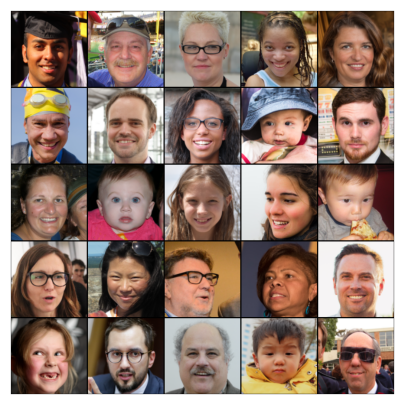

In [12]:
show_batch(dataloader)

## Часть 2. Построение и обучение модели (4 балла)

Сконструируйте генератор и дискриминатор. Помните, что:
* дискриминатор принимает на вход изображение (тензор размера `3 x image_size x image_size`) и выдает вероятность того, что изображение настоящее (тензор размера 1)

* генератор принимает на вход тензор шумов размера `latent_size x 1 x 1` и генерирует изображение размера `3 x image_size x image_size`

In [53]:
discriminator = nn.Sequential(
    # 3 * 128 * 128
    nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
    nn.LeakyReLU(0.2, inplace=True),

    # 32 * 64 * 64
    nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
    nn.LeakyReLU(0.2, inplace=True),

    # 64 * 32 * 32
    nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
    nn.LeakyReLU(0.2, inplace=True),

    # 128 * 16 * 16
    nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
    nn.LeakyReLU(0.2, inplace=True),

    # 256 * 8 * 8
    nn.Conv2d(256, 512, kernel_size=4, stride=2, padding=1),
    nn.LeakyReLU(0.2, inplace=True),

    # 512 * 4 * 4
    nn.Conv2d(512, 1, kernel_size=4, stride=2, padding=0),

    nn.Flatten(),
    nn.Sigmoid()
)

dicriminator = discriminator.to(device)

In [54]:
latent_size = 256 # choose latent size

In [55]:
generator = nn.Sequential(
    # latent_size * 1 * 1
    nn.ConvTranspose2d(latent_size, 512, kernel_size=4, stride=1, padding=0),
    nn.ReLU(inplace=True),

    # 512 * 4 * 4
    nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
    nn.BatchNorm2d(256),
    nn.ReLU(inplace=True),

    # 256 * 8 * 8
    nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
    nn.BatchNorm2d(128),
    nn.ReLU(inplace=True),

    # 128 * 16 * 16
    nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
    nn.BatchNorm2d(64),
    nn.ReLU(inplace=True),

    # 64 * 32 * 32
    nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
    nn.BatchNorm2d(32),
    nn.ReLU(inplace=True),

    # 32 * 64 * 64
    nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
    nn.Tanh()

    # 3 * 128 * 128
)

generator = generator.to(device)

torch.Size([128, 3, 128, 128])


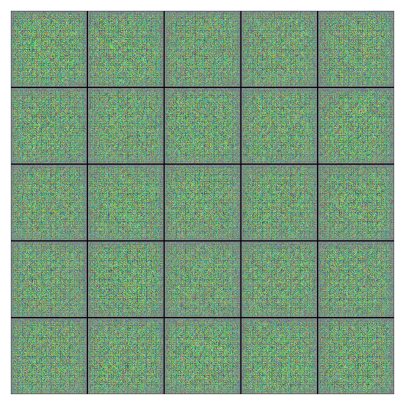

In [16]:
xb = torch.randn(batch_size, latent_size, 1, 1, device=device)
fake_images = generator(xb)
print(fake_images.shape)
show_images(fake_images.detach().cpu())

Перейдем теперь к обучению нашего GANа. Алгоритм обучения следующий:
1. Учим дискриминатор:
  * берем реальные изображения и присваиваем им метку 1
  * генерируем изображения генератором и присваиваем им метку 0
  * обучаем классификатор на два класса

2. Учим генератор:
  * генерируем изображения генератором и присваиваем им метку 0
  * предсказываем дискриминаторором, реальное это изображение или нет


В качестве функции потерь берем бинарную кросс-энтропию

In [17]:
sample_dir = 'generated'
os.makedirs(sample_dir, exist_ok=True)

In [18]:
fixed_latent = torch.randn(25, latent_size, 1, 1, device=device)

In [19]:
def save_samples(index, latent_tensors, show=True):
    fake_images = generator(latent_tensors)
    fake_fname = 'generated-images-{0:0=4d}.png'.format(index)
    save_image(denorm(fake_images), os.path.join(sample_dir, fake_fname), nrow=5)
    print('Saving', fake_fname)
    if show:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.set_xticks([]); ax.set_yticks([])
        ax.imshow(make_grid(fake_images.cpu().detach(), nrow=5).permute(1, 2, 0))

In [56]:
lr = 0.0001
num_epochs = 25

model = {
    "discriminator": discriminator,
    "generator": generator
}

criterion = {
    "discriminator": nn.BCELoss(),
    "generator": nn.BCELoss()
}

In [57]:
def fit(model, criterion, num_epochs, lr, start_idx=1):
    # TODO: build optimizers and train your GAN

    model['discriminator'].train()
    model['generator'].train()
    torch.cuda.empty_cache()

    losses_g = []
    losses_d = []
    real_scores = []
    fake_scores = []

    optimizer = {
        'discriminator': torch.optim.Adam(model['discriminator'].parameters(), lr=lr, betas=(0.5, 0.999)),
        'generator': torch.optim.Adam(model['generator'].parameters(), lr=2*lr, betas=(0.5, 0.999))
    }

    for epoch in tqdm(range(num_epochs)):
        print()
        loss_g_per_epoch = []
        loss_d_per_epoch = []
        real_score_per_epoch = []
        fake_score_per_epoch = []

        for real_images in tqdm(dataloader):
            real_images = real_images.to(device)
            # train dicriminator
            optimizer['discriminator'].zero_grad()

            real_preds = model['discriminator'](real_images)
            real_targets = torch.ones(real_images.size(0), 1, device=device)
            real_loss = criterion['discriminator'](real_preds, real_targets)
            cur_real_score = torch.mean(real_preds).item()

            latent = torch.randn(batch_size, latent_size, 1, 1, device=device)
            fake_images = model['generator'](latent).detach()

            fake_targets = torch.zeros(fake_images.size(0), 1, device=device)
            fake_preds = model['discriminator'](fake_images)
            fake_loss = criterion['discriminator'](fake_preds, fake_targets)
            cur_fake_score = torch.mean(fake_preds).item()

            real_score_per_epoch.append(cur_real_score)
            fake_score_per_epoch.append(cur_fake_score)

            loss_d = real_loss + fake_loss
            loss_d.backward()

            optimizer['discriminator'].step()
            loss_d_per_epoch.append(loss_d.item())

            # train generator
            optimizer['generator'].zero_grad()

            latent = torch.randn(batch_size, latent_size, 1, 1, device=device)
            fake_images = model['generator'](latent)

            preds = model['discriminator'](fake_images)
            targets = torch.ones(fake_images.size(0), 1, device=device)
            loss_g = criterion['generator'](preds, targets)

            loss_g.backward()
            optimizer['generator'].step()
            loss_g_per_epoch.append(loss_g.item())

        losses_g.append(np.mean(loss_g_per_epoch))
        losses_d.append(np.mean(loss_d_per_epoch))
        real_scores.append(np.mean(real_score_per_epoch))
        fake_scores.append(np.mean(fake_score_per_epoch))

        print(f'Epoch [{epoch + 1}/{num_epochs}]: loss_g: {losses_g[-1]:.2f}, loss_d: {losses_d[-1]:.2f}, real_score: {real_scores[-1]:.2f}, fake_score: {fake_scores[-1]:.2f}')

        if epoch == num_epochs - 1:
            save_samples(epoch + start_idx, fixed_latent, show=False)

    return losses_g, losses_d, real_scores, fake_scores


In [58]:
statistics = fit(model, criterion, num_epochs, lr)

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

Epoch [1/25]: loss_g: 2.08, loss_d: 0.76, real_score: 0.77, fake_score: 0.34



  0%|          | 0/25 [00:00<?, ?it/s]

Epoch [2/25]: loss_g: 4.05, loss_d: 0.32, real_score: 0.91, fake_score: 0.12



...

Epoch [23/25]: loss_g: 0.90, loss_d: 1.37, real_score: 0.52, fake_score: 0.48



  0%|          | 0/25 [00:00<?, ?it/s]

Epoch [24/25]: loss_g: 0.80, loss_d: 1.31, real_score: 0.52, fake_score: 0.47



  0%|          | 0/25 [00:00<?, ?it/s]

Epoch [25/25]: loss_g: 0.78, loss_d: 1.37, real_score: 0.51, fake_score: 0.49
Saving generated-images-0025.png


Постройте графики лосса для генератора и дискриминатора. Что вы можете сказать про эти графики?

In [59]:
losses_g, losses_d, real_scores, fake_scores = statistics

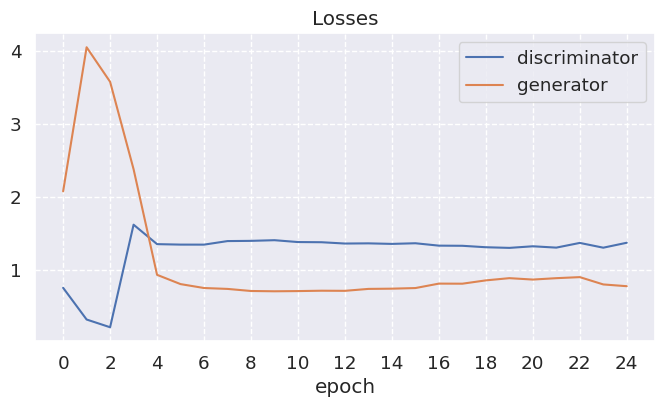

In [60]:
plt.figure(figsize=(8, 4))
plt.title('Losses')

plt.plot(losses_d, label='discriminator')
plt.plot(losses_g, label='generator')

plt.xticks(range(0, num_epochs, 2))
plt.xlabel('epoch')

plt.legend()
plt.grid(linestyle='--')

plt.show()

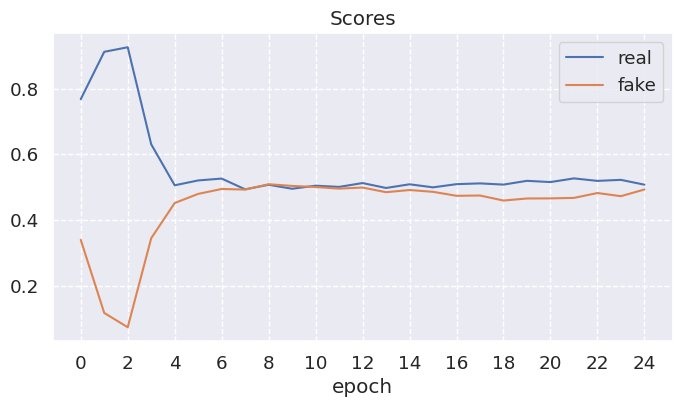

In [61]:
plt.figure(figsize=(8, 4))
plt.title('Scores')

plt.plot(real_scores, label='real')
plt.plot(fake_scores, label='fake')

plt.xticks(range(0, num_epochs, 2))
plt.xlabel('epoch')

plt.legend()
plt.grid(linestyle='--')

plt.show()

У дискриминатора лосс растет, у генератора лосс падает. 

real и fake score стремятся к ~ 0.5.

## Часть 3. Генерация изображений

Теперь давайте оценим качество получившихся изображений. Напишите функцию, которая выводит изображения, сгенерированные нашим генератором

In [67]:
n_images = 4

fixed_latent = torch.randn(n_images, latent_size, 1, 1, device=device)
fake_images = model["generator"](fixed_latent)

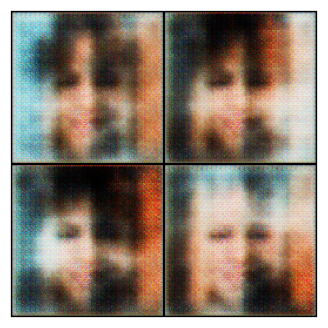

In [59]:
def show_generated(generated):
    # TODO: show generated images
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.set_xticks([]); ax.set_yticks([])
    ax.imshow(make_grid(denorm(generated), nrow=2).permute(1, 2, 0))

show_generated(fake_images.detach().cpu())

Как вам качество получившихся изображений?

Получается отдаленно разглядеть черты лица, уже неплохо.

## Часть 4. Leave-one-out-1-NN classifier accuracy (5 баллов)

### 4.1. Подсчет accuracy (3 балл)

Не всегда бывает удобно оценивать качество сгенерированных картинок глазами. В качестве альтернативы вам предлагается реализовать следующий подход:
  * Сгенерировать столько же фейковых изображений, сколько есть настоящих в обучающей выборке. Присвоить фейковым метку класса 0, настоящим – 1.
  * Построить leave-one-out оценку: обучить 1NN Classifier (`sklearn.neighbors.KNeighborsClassifier(n_neighbors=1)`) предсказывать класс на всех объектах, кроме одного, проверить качество (accuracy) на оставшемся объекте. В этом вам поможет `sklearn.model_selection.LeaveOneOut`

In [69]:
cnt = 500
real_images = data[:cnt]
real_targets = torch.ones(cnt, 1, device=device)

latent = torch.randn(cnt, latent_size, 1, 1, device=device)
fake_images = model['generator'](latent)
fake_targets = torch.zeros(cnt, 1, device=device)

In [70]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import accuracy_score

In [71]:
real_images = torch.stack(real_images, dim=0)
real_images = real_images.to(device)

In [72]:
images = torch.cat((real_images, fake_images), dim=0)
targets = torch.cat((real_targets, fake_targets), dim=0)

In [73]:
accuracy_vals = []

loo = LeaveOneOut()
loo.get_n_splits(images)

images_2d = images.view(images.shape[0], -1)
targets = targets.ravel()

for i, (train_index, test_index) in enumerate(loo.split(images)):
    X_train, y_train = images_2d[train_index].detach().cpu(), targets[train_index].detach().cpu()
    X_test, y_test = images_2d[test_index].detach().cpu(), targets[test_index].detach().cpu()
    
    knn = KNeighborsClassifier(n_neighbors=1)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)
    
    accuracy_vals.append(accuracy_score(y_pred, y_test))

print(f'Mean accuracy = {np.mean(accuracy_vals)}')

Mean accuracy = 0.95


Что вы можете сказать о получившемся результате? Какой accuracy мы хотели бы получить и почему?

Среднее accuracy = 0.95, что означает, что knn почти всегда классифицирует верно, т.е. он достаточно хорошо различает сгенерированные картинки от настоящих. Хотелось бы получить наоборот низкое значение accuracy, потому что в этом случае настоящие и сгенерированные изображения были бы очень похожи друг на друга.

### 4.2. Визуализация распределений (2 балл)

Давайте посмотрим на то, насколько похожи распределения настоящих и фейковых изображений. Для этого воспользуйтесь методом, снижающим размерность (к примеру, TSNE) и изобразите на графике разным цветом точки, соответствующие реальным и сгенерированным изображениям

In [74]:
from sklearn.manifold import TSNE

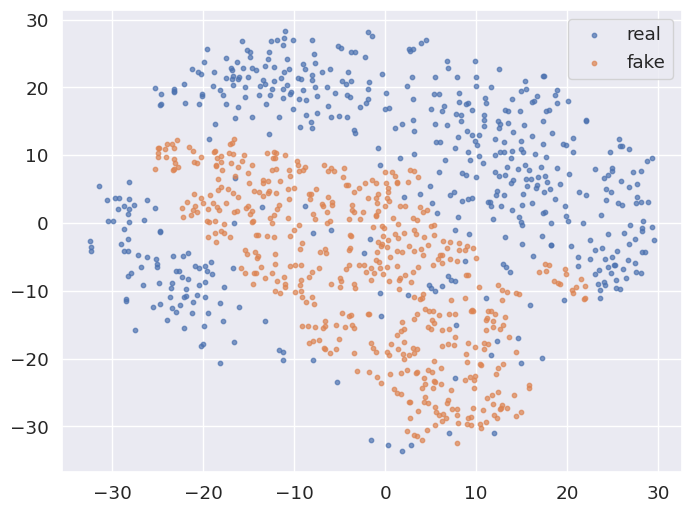

In [75]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
images_tsne = tsne.fit_transform(images_2d.detach().cpu())

plt.figure(figsize=(8, 6))

plt.scatter(images_tsne[:500, 0], images_tsne[:500, 1], label='real', s=10, alpha=0.7)
plt.scatter(images_tsne[500:, 0], images_tsne[500:, 1], label='fake', s=10, alpha=0.7)

plt.legend()
plt.show()

Прокомментируйте получившийся результат:

Как видно из графика распределений, распределения настоящих и сгенерированных изображений отличаются. Их, конечно, нельзя идеально разделить даже нелинейной поверхностью, но все же они почти не смешиваются.